# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
# from google.colab import files   # only needed on Google Colab

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [2]:
df = pd.read_csv("dataset/Lab_11_QnA_Dataset.csv")   # on Colab: "/content/Lab_11_QnA_Dataset_Download.csv"
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())

Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [3]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [4]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

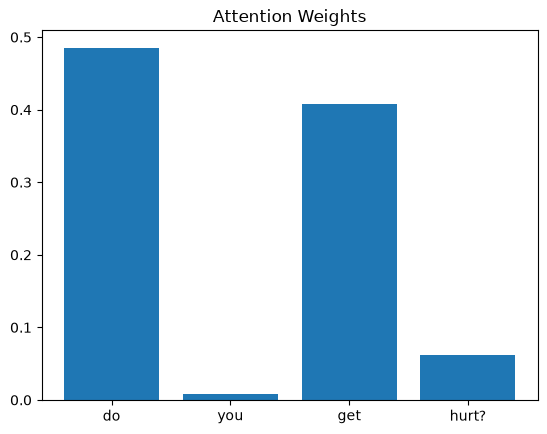

In [6]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

**Step 1 - A function that draws the attention chart of one question.** It is Step 6 of the lab wrapped in a function: take the question at `index`, run the model on its padded sequence, keep the weights of the real words (not the padding), draw the bar chart, and report the word with the highest weight together with the true and predicted answers.

In [7]:
def plot_attention(index):
    question = df["question"][index]
    words = question.split()

    with torch.no_grad():
        prediction, weights = model(X[index:index + 1])
    w = weights[0, :len(words)].tolist()                     # one weight per real word
    predicted_answer = df.loc[df["answer_id"] == prediction.argmax().item(), "answer"].iloc[0]

    plt.figure(figsize=(6, 3))
    plt.bar(words, w)
    plt.title(f"Attention weights: '{question}'")
    plt.ylabel("weight")
    plt.show()

    top_word = words[int(torch.tensor(w).argmax())]
    print(f"Question        : {question}")
    print(f"True answer     : {df['answer'][index]}")
    print(f"Predicted answer: {predicted_answer}")
    print(f"Highest weight  : '{top_word}' ({max(w):.3f})\n")

**Step 2 - Three different questions from three answer groups.** Index 0 is the lab's question ("Do you get hurt?", the body group), 44 is "Which company programmed you?" (the "who made you" group) and 115 is "Do you have a name?" (the name group).

In [8]:
for index in [0, 44, 115]:
    print("Question", index, ":", df["question"][index], "| answer group", df["answer_id"][index])

Question 0 : do you get hurt? | answer group 0
Question 44 : which company programmed you? | answer group 3
Question 115 : do you have a name? | answer group 8


**Step 3 - Draw the three charts.**

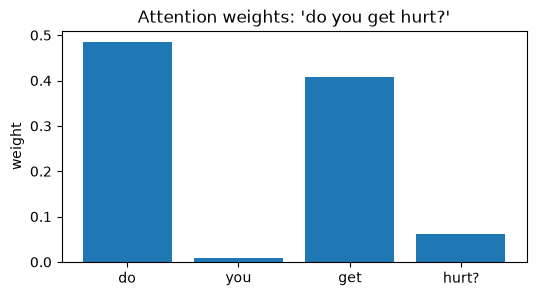

Question        : do you get hurt?
True answer     : I don't have a body.
Predicted answer: I don't have a body.
Highest weight  : 'do' (0.485)



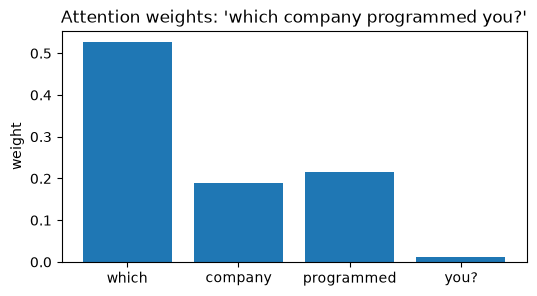

Question        : which company programmed you?
True answer     : People created me.
Predicted answer: People created me.
Highest weight  : 'which' (0.527)



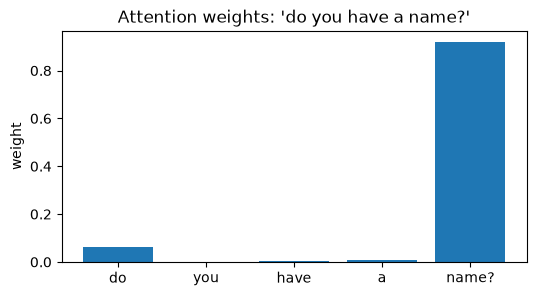

Question        : do you have a name?
True answer     : I don't have a name.
Predicted answer: I'm better at answering questions.
Highest weight  : 'name?' (0.920)



In [9]:
for index in [0, 44, 115]:
    plot_attention(index)

**Answer.** In one of the three questions the highest weight is on the word a person would pick: "name?" gets 0.92 of the attention in "Do you have a name?". In the other two the top weight goes to the first, grammatical word ("do" in "Do you get hurt?", "which" in "Which company programmed you?") while the content words ("hurt", "programmed") get less, so the attention weights are only partly aligned with what makes the question understandable. Two things explain this: the model is small and trained on 168 questions, and the lab's training loop never calls `optimizer.zero_grad()`, so the gradients of all epochs add up and the model stays weak (it even predicts the wrong group for "Do you have a name?" although it attends to the right word). Attention tells us where the model looks, not that the model is right, and here it often looks at the first word because the RNN state at that position already carries the whole question through the recurrence.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

**Step 1 - Choose two pairs of questions with the same meaning but different words.** The first pair shares the key word "programmed"; the second pair ("Do you have a name?" / "Who are you?") shares no word at all.

In [10]:
pairs = [
    ("Who programmed you?", "Which company programmed you?"),
    ("Do you have a name?", "Who are you?"),
]

**Step 2 - A helper that returns the attention weights of a question.** It finds the question in the dataset, passes its padded sequence through the trained model, and returns the words, their weights and the predicted answer group.

In [11]:
def attention_for(question_text):
    index = df.index[df["question"].str.lower() == question_text.lower()][0]
    words = df["question"][index].split()
    with torch.no_grad():
        prediction, weights = model(X[index:index + 1])
    return words, weights[0, :len(words)].tolist(), prediction.argmax().item()

**Step 3 - Plot each pair side by side.** For each question the chart title shows the predicted answer group, the label under the chart names the word with the highest weight, and the same facts are printed as text (true group, predicted group, top word).

Who programmed you?              true group 3, predicted 3, highest weight on 'programmed' (0.483)
Which company programmed you?    true group 3, predicted 3, highest weight on 'which' (0.527)


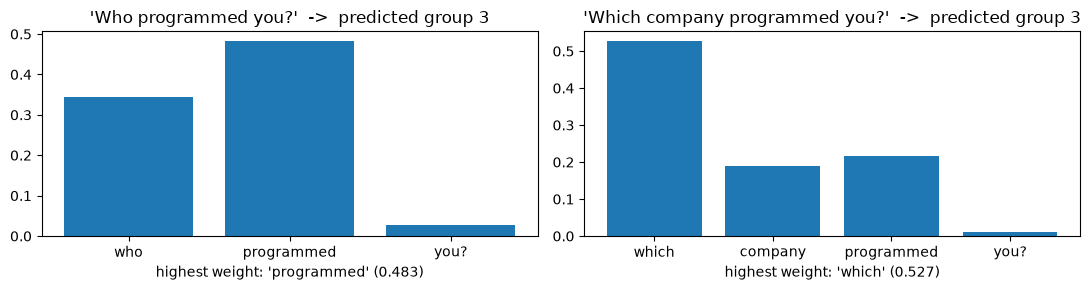


Do you have a name?              true group 8, predicted 2, highest weight on 'name?' (0.920)
Who are you?                     true group 8, predicted 3, highest weight on 'are' (0.401)


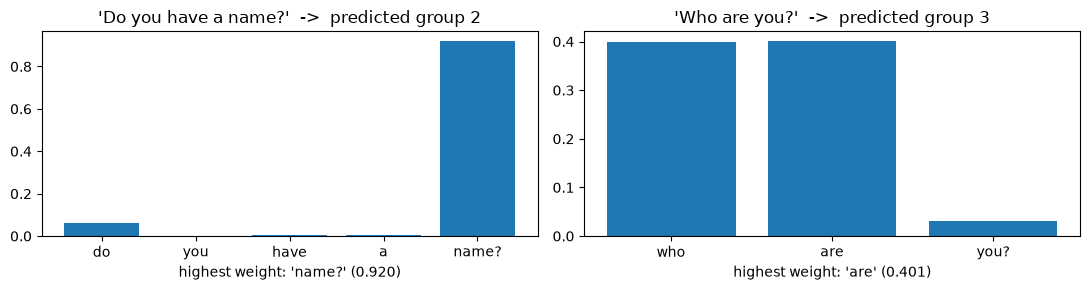

In [12]:
for q1, q2 in pairs:
    fig, axes = plt.subplots(1, 2, figsize=(11, 3))
    for ax, q in zip(axes, (q1, q2)):
        words, w, pred = attention_for(q)
        true_group = int(df.loc[df["question"].str.lower() == q.lower(), "answer_id"].iloc[0])
        top = words[int(torch.tensor(w).argmax())]
        ax.bar(words, w)
        ax.set_title(f"'{q}'  ->  predicted group {pred}")
        ax.set_xlabel(f"highest weight: '{top}' ({max(w):.3f})")
        print(f"{q:32s} true group {true_group}, predicted {pred}, highest weight on '{top}' ({max(w):.3f})")
    plt.tight_layout()
    plt.show()
    print()

**Answer.** For the pair with the same key word the model focuses on a similar place: "Who programmed you?" puts its highest weight on "programmed" and "Which company programmed you?" gives "programmed" a large share too (its top weight is "which"), and both are predicted correctly as the same answer group. For the pair with no shared word, "Do you have a name?" attends almost entirely to "name?" (0.92) while "Who are you?" spreads its weight and lands on "are", and both are mispredicted (groups 2 and 3 instead of 8). So the model focuses on similar words when similar questions share them and on different words when they do not. This suggests attention works lexically here: it learns which input positions matter for the prediction and concentrates on them, which makes paraphrases with the same key word behave alike, but it cannot by itself recognise that two differently worded questions mean the same thing; that would need word vectors trained on far more text (or a pre-trained model such as the transformers of Lab 7).